In [1]:
from anemone.system import Loop, Receiver, lamontagne, getRz, rdtype
import torch
import matplotlib.pyplot as plt
import numpy as np

torch detected, enabling torch tensor support in nosj


In [167]:
tx = Loop.square(40.)
rx = Receiver()
R = torch.logspace(torch.log10(tx.min_horizontal_distance(rx)/2.), torch.log10(tx.max_horizontal_distance(rx)*2.), steps=51)


In [168]:
def geomz0(self, rx, R, ix=500):
    if hasattr(self, 'radius') and rx.xyz.numel()==3 and rx.x==0. and rx.y==0.:
        return self._geomz_circle(rx, R)
    logR = torch.log(R).cpu()
    dR = logR[1]-logR[0]

    rx_xyz = rx.xyz
    n_rec  = len(rx)

    geomz      = torch.zeros((n_rec, )+R.shape, dtype=rdtype)

    R      = R [None, None, :]
    
    lp_xyz = self.xyz[:, None] - rx_xyz[None, :]
    
    for i in range(len(self)-1):
    
        Rz,iRz = getRz(lp_xyz[i], lp_xyz[i+1])
        p1 = torch.einsum('...ij,...j->...i', Rz, lp_xyz[i])
        p2 = torch.einsum('...ij,...j->...i', Rz, lp_xyz[i+1])
        x1,y1 = p1[..., 0], p1[..., 1]
        x2,y2 = p2[..., 0], p2[..., 1]
        ix = int(100*torch.abs(x2-x1).max())
        
        tmpx = torch.linspace(-1, 1, ix)
        x_samp = tmpx
        x_samp += 1.
        length = torch.abs(x2-x1)/2.


        x_ = (x1[:,None] + length[:,None]*x_samp[None, :])
        dx = (x_[..., 1] - x_[..., 0])[:,None]
        
        x1 = x1[:, None]
        x2 = x2[:, None]
        y1 = y1[:, None, None]
        x_ = x_[:, :, None]
        dx = dx[:, None]


        cr = torch.sqrt(y1**2 + x_**2)
        phi = lamontagne((torch.log(cr)-logR)/dR)
        cs =  -y1 * phi * dx / cr
        geomz += cs.sum(axis=1, keepdims=False)
    return geomz.to(R.device)

In [217]:
def geomz1(self, rx, R):
    logR = torch.log(R).cpu()
    dR = logR[1]-logR[0]

    rx_xyz = rx.xyz
    n_rec  = len(rx)

    geomz      = torch.zeros((n_rec, )+R.shape, dtype=rdtype)
    
    phi_func = Spline(R, log_sampled=True)

    R      = R [None, None, :]
    
    lp_xyz = self.xyz[:, None] - rx_xyz[None, :]
    



    for i in range(len(self)-1):
    
        Rz,iRz = getRz(lp_xyz[i], lp_xyz[i+1])
        p1 = torch.einsum('...ij,...j->...i', Rz, lp_xyz[i])
        p2 = torch.einsum('...ij,...j->...i', Rz, lp_xyz[i+1])
        x1,y1 = p1[..., 0], p1[..., 1]
        x2,y2 = p2[..., 0], p2[..., 1]
        r1_min,r1_max = y1.abs().min(), (y1.abs()**2 + x1.max()**2)**0.5
        r2_min,r2_max = y2.abs().min(), (y2.abs()**2 + x2.max()**2)**0.5

        dx = (x2 - x1)

        cr = R.squeeze().to(rdtype)
        cs =  (cr**2-y1**2)**-0.5
        cs[cr<=r1_min] = 0.
        cs *= -y1
        geomz1 = phi_func.integrate(r1_min, r1_max)*cs
        
        
        cs =  (cr**2-y2**2)**-0.5
        cs[cr<=r2_min] = 0.

        cs *= -y2

        geomz2 = phi_func.integrate(r2_min, r2_max)*cs
        some_x = (geomz1+geomz2).sum()
        ds = dx-some_x
        print(ds)
        phi = lamontagne((torch.log(r2_min)-logR)/dR)
        geomz += geomz1 + geomz2 - y2*phi*ds/cr

    return geomz

int0 =  lambda x: -0.0277777777777778*x**6 - 0.25*x**5 - 0.791666666666667*x**4 - 0.916666666666667*x**3 + 0.166666666666667*x**2 + 1.0*x
int1 =  lambda x: 0.0833333333333333*x**6 + 0.25*x**5 - 0.125*x**4 - 0.75*x**3 + 1.0*x
int2 =  lambda x: -0.0833333333333333*x**6 + 0.25*x**5 + 0.125*x**4 - 0.75*x**3 + 1.0*x
int3 =  lambda x: 0.0277777777777778*x**6 - 0.25*x**5 + 0.791666666666667*x**4 - 0.916666666666667*x**3 - 0.166666666666667*x**2 + 1.0*x

def int_lamontagne(x):
    phi   = x*0.
    xm2m1 = (-2 <= x)*(x < -1)
    xm1m0 = (-1 <= x)*(x < 0)
    x0p1  = (0 <= x)*(x <= 1)
    x1p2  = (1 < x)*(x <= 2)

    phi[xm2m1] = int0(x[xm2m1])
    phi[xm1m0] = int1(x[xm1m0])
    phi[x0p1]  = int2(x[x0p1])
    phi[x1p2]  = int3(x[x1p2])
    return phi

class Spline:
    def __init__(self, x, log_sampled=False, epsilon=1e-6):
        self.x0 = torch.log(x) if log_sampled else x
        self.dx = self.x0[1]-self.x0[0]        
        if log_sampled:
            self.transform = lambda x: (torch.log(x)-self.x0[0])/self.dx    
        else:
            self.transform = lambda x: (x-self.x0[0])/self.dx
        self.x = self.transform(x)
        self.log_sampled = log_sampled

        self.i_full = torch.arange(-2, 3).to(rdtype)
        self.phi_ubnd = int_lamontagne(1-epsilon - self.i_full)
        self.phi_lbnd = int_lamontagne(epsilon - self.i_full)
        self.phi_full = self.phi_ubnd - self.phi_lbnd

        self.epsilon = epsilon

    def integrate(self, x_lower, x_upper, lin_weight=None):
        if lin_weight is None:
            m,b=0.,1.
        else:
            m,b = lin_weight
        kernel = m*self.x0 + b

        x_lb = self.transform(x_lower)
        x_ub = self.transform(x_upper)

        x_lb += self.epsilon
        x_ub -= self.epsilon

        i_lbnd = torch.searchsorted(self.x, x_lb)-1
        i_ubnd = torch.searchsorted(self.x, x_ub)#-1
        assert i_lbnd-2 >= 0
        assert i_ubnd+2 <= len(self.x)

        
        int_phi = torch.zeros_like(self.x)
        for i in range(i_lbnd, i_ubnd+2):
            i_slc = slice(i-3, i+2)
            if   i==i_lbnd:
                int_phi[i_slc] += torch.nan_to_num((self.phi_ubnd-int_lamontagne(x_lb-self.x[i-1] - self.i_full))*kernel[i_slc])
            elif i==i_ubnd:
                int_phi[i_slc] += torch.nan_to_num((int_lamontagne(x_ub-self.x[i-1] - self.i_full)-self.phi_lbnd)*kernel[i_slc])
            elif i>i_lbnd and i<i_ubnd:
                int_phi[i_slc] += torch.nan_to_num(self.phi_full*kernel[i_slc])
        result = int_phi*self.dx
        if self.log_sampled:
            result *= torch.exp(self.x0)
        return result


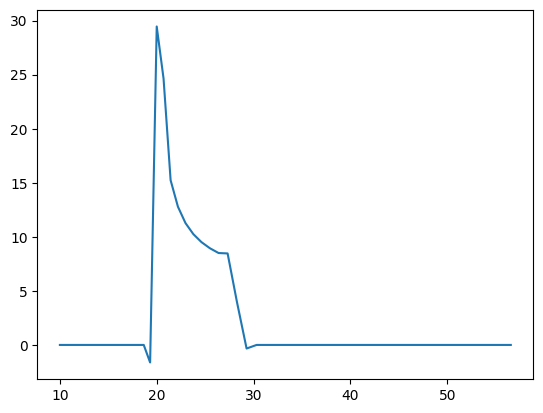

In [218]:
plt.figure()
for i in [10000]:
    s0 = geomz0(tx, rx, R, ix=i).squeeze()
    plt.plot(R.numpy(), s0.numpy())

In [219]:
s1 = geomz1(tx, rx, R).squeeze()

tensor([12.4535], dtype=torch.float64)
tensor([12.4535], dtype=torch.float64)
tensor([12.4535], dtype=torch.float64)
tensor([12.4535], dtype=torch.float64)


C:\Users\au646858\AppData\Local\Temp\ipykernel_36124\1683358857.py:4: RuntimeWarning: invalid value encountered in divide
  axs[1].semilogx(R.numpy(), (s0-s1).numpy()/s0.numpy())


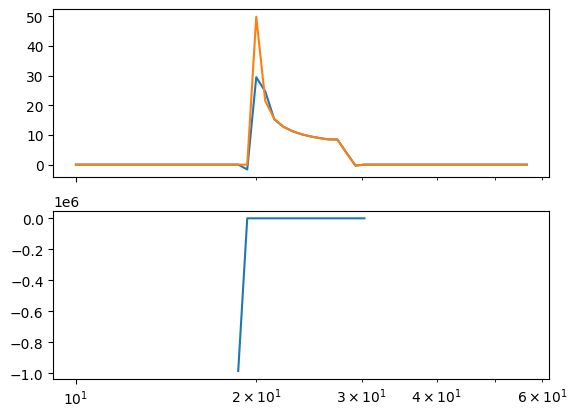

In [220]:
fig,axs = plt.subplots(2,1, sharex=True)
axs[0].semilogx(R.numpy(), s0.numpy())
axs[0].semilogx(R.numpy(), s1.numpy())
axs[1].semilogx(R.numpy(), (s0-s1).numpy()/s0.numpy())

